# 01 · Exploratory data analysis and preprocessing

Input: the full arXiv metadata snapshot (`Cornell-University/arxiv` on Kaggle).
Output: EDA figures and statistics, plus `train/val/test.parquet` used by the later notebooks.

Runs on a CPU session (~15 min); no GPU needed.

In [1]:
import gc
import glob
import shutil
import sys
from pathlib import Path


def add_src_to_path():
    """Locally the repo root is the parent of notebooks/; on Kaggle `src` is attached as a dataset."""
    hits = glob.glob("/kaggle/input/**/taxonomy.py", recursive=True)
    if hits:
        pkg = Path("/tmp/pkg/src")
        shutil.copytree(Path(hits[0]).parent, pkg, dirs_exist_ok=True)
        sys.path.insert(0, str(pkg.parent))
    else:
        sys.path.insert(0, str(Path.cwd().parent))


add_src_to_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

from src import preprocess, taxonomy, viz
from src.utils import DATA_DIR, FIG_DIR, RESULTS_DIR, ensure_dirs, find_input, save_json, set_seed

set_seed()
ensure_dirs()
viz.apply_style()
pd.set_option("display.max_columns", 20)

MIN_PER_CLASS = 500  # drop fine categories with fewer primary papers than this
CAP_PER_CLASS = 500  # papers sampled per fine category
stats = {}

## 1. Load
The snapshot is JSON-lines, one record per paper. We keep id, title, abstract, categories,
comments (used to spot withdrawals), last update date and the year of the first version.

In [2]:
raw_path = find_input("arxiv-metadata-oai-snapshot.json")
df = preprocess.load_raw(raw_path)
df = preprocess.add_labels(df)
stats["n_papers_raw"] = len(df)
print(f"{len(df):,} papers")
df.head(3)

3,215,335 papers


,id,title,abstract,categories,comments,update_date,year,n_categories,fine,archive,group
0,0704.0001,Calculation of prompt diphoton production cros...,A fully differential calculation in perturba...,hep-ph,"37 pages, 15 figures; published version",2008-11-26,2007,1,hep-ph,hep-ph,Physics
1,0704.0002,Sparsity-certifying Graph Decompositions,"We describe a new algorithm, the $(k,\ell)$-...",math.CO cs.CG,To appear in Graphs and Combinatorics,2008-12-13,2007,2,math.CO,math,Mathematics
2,0704.0003,The evolution of the Earth-Moon system based o...,The evolution of Earth-Moon system is descri...,physics.gen-ph,"23 pages, 3 figures",2008-01-13,2007,1,physics.gen-ph,physics,Physics


In [3]:
df.isna().sum().to_frame("missing")

,missing
id,0
title,0
abstract,0
categories,0
comments,907073
update_date,0
year,0
n_categories,0
fine,0
archive,0


## 2. How many categories are there?
The primary category is the first one listed. Legacy names (e.g. `alg-geom`) and official
aliases (e.g. `math.MP` = `math-ph`) are mapped to their canonical modern category.

{'group': 8, 'archive': 20, 'fine': 151}


PosixPath('/kaggle/working/reports/figures/fig01_groups.png')

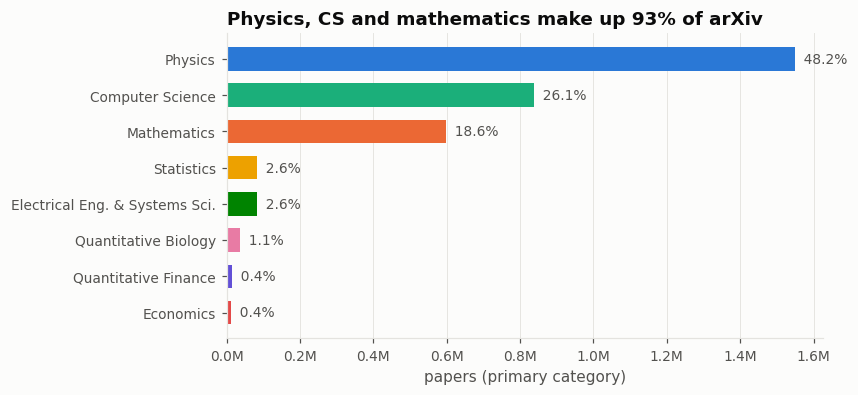

In [4]:
levels = {lvl: df[lvl].nunique() for lvl in ["group", "archive", "fine"]}
stats["n_classes_raw"] = levels
print(levels)

group_counts = df["group"].value_counts()
stats["group_counts"] = group_counts.to_dict()

fig, ax = plt.subplots(figsize=(7, 3.6))
order = list(group_counts.index[::-1])  # largest at the top
ax.barh(order, group_counts[order], color=[viz.GROUP_COLORS[g] for g in order], height=0.65)
for i, g in enumerate(order):
    ax.text(group_counts[g], i, f"  {group_counts[g] / len(df):.1%}", va="center", fontsize=9, color=viz.TEXT_2)
ax.set_xlabel("papers (primary category)")
ax.set_title(f"Physics, CS and mathematics make up {group_counts.head(3).sum() / len(df):.0%} of arXiv")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1e6:.1f}M")
viz.save(fig, "fig01_groups", FIG_DIR)

### The long tail of fine categories

fine
cs.CV                163892
cs.LG                148893
hep-ph               145545
quant-ph             138590
hep-th               115233
cs.CL                 91007
cond-mat.mtrl-sci     73870
gr-qc                 73869
cond-mat.mes-hall     71067
math.AP               61044
math.CO               57136
astro-ph.GA           57034
cond-mat.str-el       53978
astro-ph.SR           49630
cs.AI                 49039
Name: count, dtype: int64

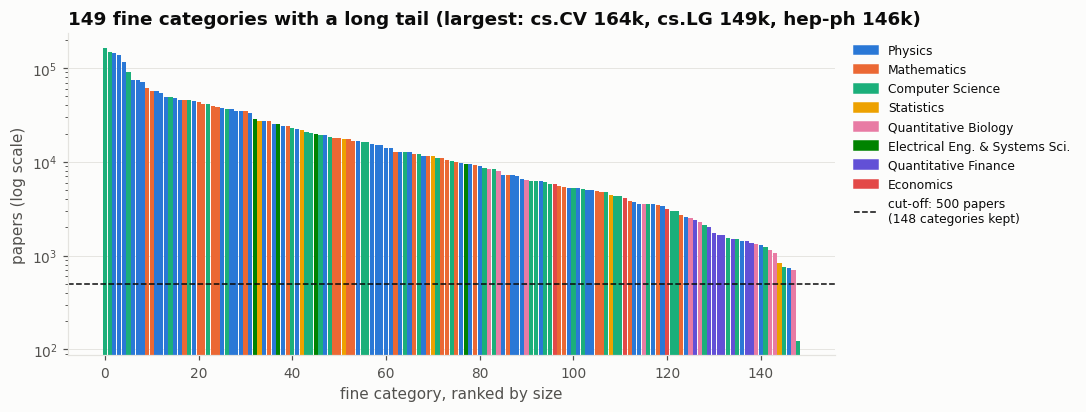

In [5]:
fine_counts = df.loc[~df["fine"].map(taxonomy.is_ambiguous_fine), "fine"].value_counts()
stats["fine_top10"] = fine_counts.head(10).to_dict()
stats["fine_bottom10"] = fine_counts.tail(10).to_dict()
stats["fine_counts"] = fine_counts.to_dict()
n_kept = int((fine_counts >= MIN_PER_CLASS).sum())

fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [viz.GROUP_COLORS[taxonomy.group_of(c)] for c in fine_counts.index]
ax.bar(np.arange(len(fine_counts)), fine_counts.values, color=colors, width=0.9)
ax.set_yscale("log")
cutoff = ax.axhline(MIN_PER_CLASS, color=viz.TEXT, lw=1, ls="--")
top3 = ", ".join(f"{c} {n / 1e3:.0f}k" for c, n in fine_counts.head(3).items())
ax.set_xlabel("fine category, ranked by size")
ax.set_ylabel("papers (log scale)")
ax.set_title(f"{len(fine_counts)} fine categories with a long tail (largest: {top3})")
handles = [plt.Rectangle((0, 0), 1, 1, color=viz.GROUP_COLORS[g]) for g in viz.GROUP_ORDER] + [cutoff]
labels = viz.GROUP_ORDER + [f"cut-off: {MIN_PER_CLASS} papers\n({n_kept} categories kept)"]
ax.legend(handles, labels, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="x", visible=False)
viz.save(fig, "fig02_long_tail", FIG_DIR)
fine_counts.head(15)

## 3. Cross-listing
Papers can list several categories. This matters for the "how many categories" question:
heavily co-listed fields are hard to separate.

PosixPath('/kaggle/working/reports/figures/fig03_cross_listing.png')

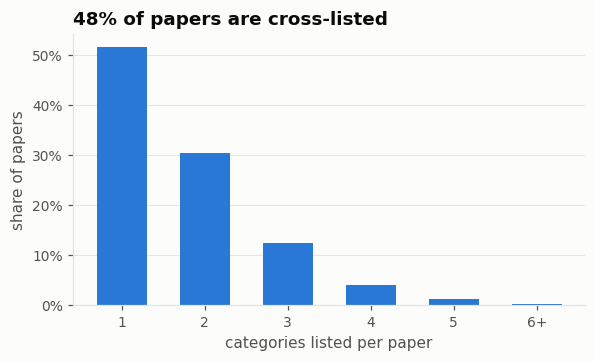

In [6]:
ncat = df["n_categories"].clip(upper=6)
cross_rate = float((df["n_categories"] > 1).mean())
stats["cross_listed_share"] = cross_rate
stats["mean_categories_per_paper"] = float(df["n_categories"].mean())

fig, ax = plt.subplots(figsize=(6, 3.2))
vc = ncat.value_counts().sort_index()
ax.bar(vc.index.astype(str).str.replace("6", "6+"), vc.values / len(df), color=viz.ACCENT, width=0.6)
ax.set_xlabel("categories listed per paper")
ax.set_ylabel("share of papers")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title(f"{cross_rate:.0%} of papers are cross-listed")
ax.grid(axis="x", visible=False)
viz.save(fig, "fig03_cross_listing", FIG_DIR)

eess     cs          0.612422
stat     cs          0.540124
hep-ex   hep-ph      0.472877
nucl-th  hep-ph      0.462976
math-ph  math        0.461321
nucl-ex  nucl-th     0.453845
gr-qc    hep-th      0.436301
hep-lat  hep-ph      0.420874
gr-qc    astro-ph    0.338449
hep-th   gr-qc       0.293423
dtype: float32

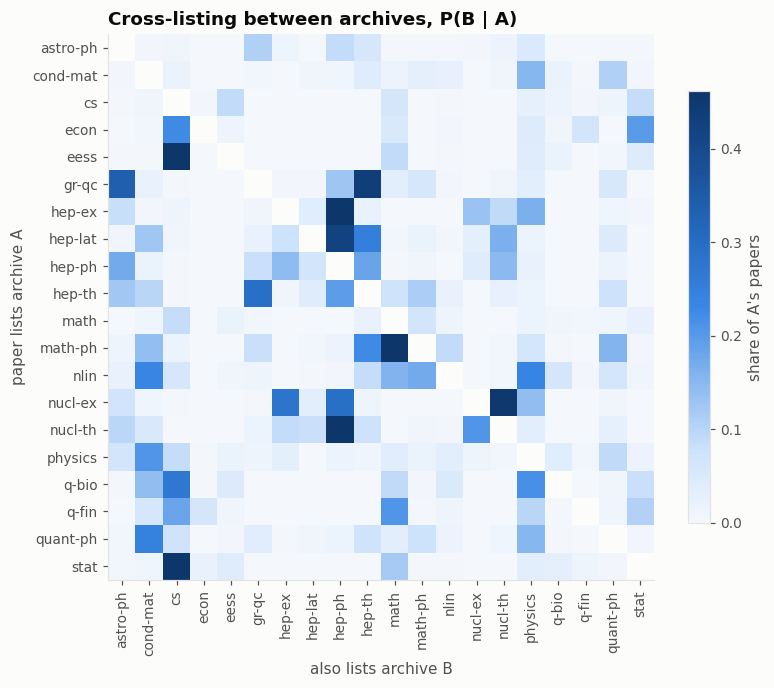

In [7]:
# Archive-level co-occurrence: P(paper also lists archive B | it lists archive A).
arch_lists = df["categories"].str.split().map(lambda cs: sorted({taxonomy.archive_of(taxonomy.canonical(c)) for c in cs}))
archives = sorted({a for lst in arch_lists for a in lst})
idx = {a: i for i, a in enumerate(archives)}
rows = np.repeat(np.arange(len(arch_lists)), arch_lists.str.len())
cols = np.fromiter((idx[a] for lst in arch_lists for a in lst), dtype=np.int64)
M = sparse.csr_matrix((np.ones_like(cols, dtype=np.float32), (rows, cols)), shape=(len(arch_lists), len(archives)))
C = (M.T @ M).toarray()
del arch_lists, rows, cols, M
P = C / np.diag(C)[:, None]
np.fill_diagonal(P, np.nan)

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(P, cmap=viz.SEQ_BLUE, vmin=0, vmax=np.nanpercentile(P, 99))
ax.set_xticks(range(len(archives)), archives, rotation=90)
ax.set_yticks(range(len(archives)), archives)
ax.grid(False)
ax.set_xlabel("also lists archive B")
ax.set_ylabel("paper lists archive A")
ax.set_title("Cross-listing between archives, P(B | A)")
fig.colorbar(im, ax=ax, shrink=0.75, label="share of A's papers")
viz.save(fig, "fig04_cooccurrence", FIG_DIR)

top_pairs = (pd.DataFrame(P, index=archives, columns=archives).stack().sort_values(ascending=False).head(10))
stats["top_cooccurrence"] = {f"{a}->{b}": round(float(v), 3) for (a, b), v in top_pairs.items()}
top_pairs

## 4. Abstract length and growth over time

PosixPath('/kaggle/working/reports/figures/fig05_abstract_length.png')

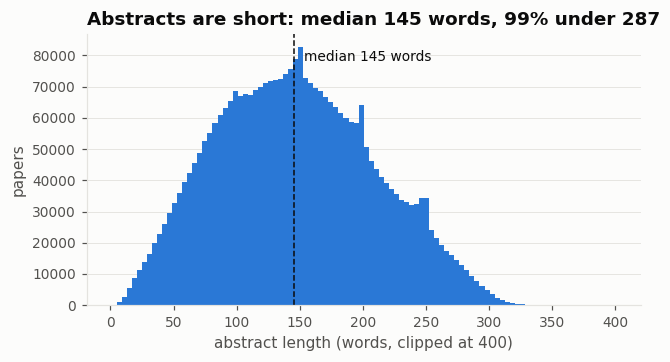

In [8]:
words = preprocess.word_count(df["abstract"])
stats["abstract_words"] = words.describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(1).to_dict()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(words.clip(upper=400), bins=100, color=viz.ACCENT)
med = words.median()
ax.axvline(med, color=viz.TEXT, lw=1, ls="--")
ax.text(med + 8, ax.get_ylim()[1] * 0.9, f"median {med:.0f} words", fontsize=9)
ax.set_xlabel("abstract length (words, clipped at 400)")
ax.set_ylabel("papers")
ax.set_title(f"Abstracts are short: median {med:.0f} words, 99% under {words.quantile(0.99):.0f}")
ax.grid(axis="x", visible=False)
viz.save(fig, "fig05_abstract_length", FIG_DIR)

/tmp/ipykernel_16/456185541.py:1: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  per_year = (df.dropna(subset=["year"]).query("1991 <= year < @df.year.max()")  # arXiv opened in 1991; last year is partial


PosixPath('/kaggle/working/reports/figures/fig06_growth.png')

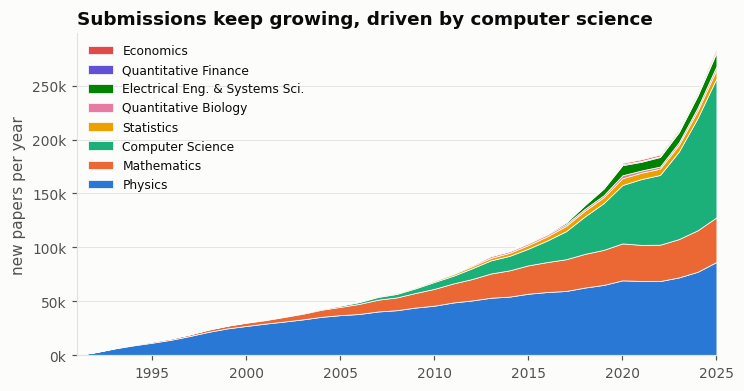

In [9]:
per_year = (df.dropna(subset=["year"]).query("1991 <= year < @df.year.max()")  # arXiv opened in 1991; last year is partial
            .groupby(["year", "group"]).size().unstack(fill_value=0))
per_year = per_year[[g for g in viz.GROUP_ORDER if g in per_year.columns]]
stats["papers_per_year_last5"] = per_year.sum(axis=1).tail(5).to_dict()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.stackplot(per_year.index.astype(int), per_year.T.values, labels=per_year.columns,
             colors=[viz.GROUP_COLORS[g] for g in per_year.columns], edgecolor=viz.SURFACE, linewidth=0.5)
ax.set_ylabel("new papers per year")
ax.yaxis.set_major_formatter(lambda x, _: f"{x / 1e3:.0f}k")
ax.set_title("Submissions keep growing, driven by computer science")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", fontsize=8)  # same top-to-bottom order as the stack
ax.set_xlim(per_year.index.min(), per_year.index.max())
ax.grid(axis="x", visible=False)
viz.save(fig, "fig06_growth", FIG_DIR)

## 5. Preprocessing
1. Remove withdrawn papers (abstract or comments say so).
2. Clean text: LaTeX math becomes `[MATH]`; citations, URLs, LaTeX commands and extra whitespace are removed.
3. Remove abstracts under 20 words and exact duplicate texts.
4. Remove papers whose primary is a bare archive that has sub-categories (e.g. pre-2009 `astro-ph`),
   which would overlap every `astro-ph.*` class.
5. Model input = `title. abstract`.

In [10]:
clean, removed = preprocess.clean_and_filter(df)
stats["preprocessing_removed"] = removed
print(removed)
ex = clean.sample(1, random_state=0).iloc[0]
print("RAW:  ", df.loc[df["id"] == ex["id"], "abstract"].iloc[0][:400])
print("CLEAN:", ex["text"][:400])

del df  # free the raw frame (~10 GB) before sampling
gc.collect()

/tmp/pkg/src/preprocess.py:101: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  withdrawn = (df["abstract"].fillna("").str.contains(_WITHDRAWN)


{'input': 3215335, 'withdrawn': 7640, 'abstract_under_20_words': 14198, 'duplicate_text': 540, 'ambiguous_bare_archive_primary': 105183, 'kept': 3087774}


RAW:   We consider time varying MIMO fading channels with known spatial and temporal correlation and solve the problem of joint carrier frequency offset (CFO) and channel estimation with prior distributions. The maximum a posteriori probability (MAP) joint estimation is proved to be equivalent to a separate MAP estimation of the CFO followed by minimum mean square error (MMSE) estimation of the channel w
CLEAN: Maximum a Posteriori Probability (MAP) Joint Carrier Frequency Offset (CFO) and Channel Estimation for MIMO Channels with Spatial and Temporal Correlations. We consider time varying MIMO fading channels with known spatial and temporal correlation and solve the problem of joint carrier frequency offset (CFO) and channel estimation with prior distributions. The maximum a posteriori probability (MAP)


12131

## 6. Sampling and splits
Fine categories with fewer than 500 primary papers are dropped; each remaining one contributes
up to 500 papers. Splits are stratified by fine category (80/10/10). The archive and group labels
are derived from the fine label, so the same split serves every label granularity.

In [11]:
train, val, test, dropped = preprocess.sample_and_split(clean, MIN_PER_CLASS, CAP_PER_CLASS)
stats["dropped_rare_categories"] = dropped.to_dict()
stats["split_sizes"] = {"train": len(train), "val": len(val), "test": len(test)}
stats["n_classes_sample"] = {lvl: int(train[lvl].nunique()) for lvl in ["group", "archive", "fine"]}
print(stats["split_sizes"], stats["n_classes_sample"])

cols = ["id", "text", "fine", "archive", "group", "year", "n_words"]
for name, part in [("train", train), ("val", val), ("test", test)]:
    part[cols].to_parquet(DATA_DIR / f"{name}.parquet", index=False)

{'train': 59200, 'val': 7400, 'test': 7400} {'group': 8, 'archive': 20, 'fine': 148}


{'n_papers_raw': 3215335,
 'n_classes_raw': {'group': 8, 'archive': 20, 'fine': 151},
 'group_counts': {'Physics': 1549158,
  'Computer Science': 839298,
  'Mathematics': 597127,
  'Statistics': 83829,
  'Electrical Eng. & Systems Sci.': 83708,
  'Quantitative Biology': 35382,
  'Quantitative Finance': 13805,
  'Economics': 13028},
 'fine_top10': {'cs.CV': 163892,
  'cs.LG': 148893,
  'hep-ph': 145545,
  'quant-ph': 138590,
  'hep-th': 115233,
  'cs.CL': 91007,
  'cond-mat.mtrl-sci': 73870,
  'gr-qc': 73869,
  'cond-mat.mes-hall': 71067,
  'math.AP': 61044},
 'fine_bottom10': {'q-bio.TO': 1334,
  'physics.atm-clus': 1302,
  'cs.MS': 1234,
  'q-bio.OT': 1134,
  'q-bio.CB': 1072,
  'stat.OT': 830,
  'cs.OS': 760,
  'nlin.CG': 738,
  'q-bio.SC': 706,
  'cs.GL': 124},
 'fine_counts': {'cs.CV': 163892,
  'cs.LG': 148893,
  'hep-ph': 145545,
  'quant-ph': 138590,
  'hep-th': 115233,
  'cs.CL': 91007,
  'cond-mat.mtrl-sci': 73870,
  'gr-qc': 73869,
  'cond-mat.mes-hall': 71067,
  'math.AP': 6

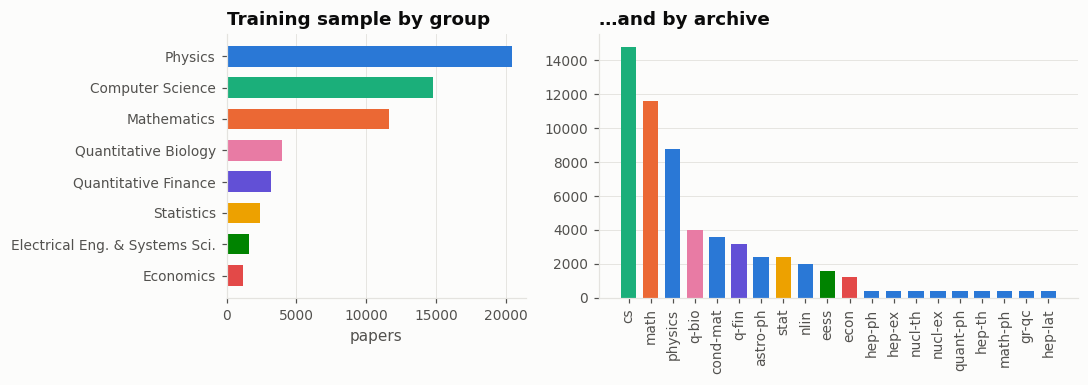

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
g = train["group"].value_counts()
axes[0].barh(g.index[::-1], g.values[::-1], color=[viz.GROUP_COLORS[x] for x in g.index[::-1]], height=0.65)
axes[0].set_title("Training sample by group")
axes[0].set_xlabel("papers")
axes[0].grid(axis="y", visible=False)
a = train["archive"].value_counts()
axes[1].bar(a.index, a.values, color=[viz.GROUP_COLORS[taxonomy.group_of(x)] for x in a.index], width=0.7)
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("…and by archive")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
viz.save(fig, "fig07_sample_classes", FIG_DIR)

save_json(stats, RESULTS_DIR / "eda_stats.json")
stats